# E4.0 — Continuous approval-month baseline

Phase 1 only: fixed LightGBM model and the current main shared framework. Explicit approval-time input: `month_index`; fixed other inputs: area, approximate flat age, town and flat type. No E4.1–E4.4, tuning, early stopping, auxiliary data or test data.

Select the project `.venv` kernel and run all cells in order from the repository root or `experiments/`. Each run creates a fresh timestamped directory under `experiments/e4/results/`; previous results are never overwritten. Outputs include metrics, environment, source hashes, checks and index-aligned validation predictions. Fit time includes preprocessing and model fitting, excludes prediction and file export.


In [1]:
import sys
sys.dont_write_bytecode = True
import hashlib
import importlib.metadata
import inspect
import json
import pickle
import platform
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "src").is_dir(), "Run from repository root or experiments/."
assert Path(sys.prefix).resolve() == (PROJECT_ROOT / ".venv").resolve(), "Select the project .venv kernel."
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline
from src.validation import load_data
from src.features import make_features, make_preprocessor
from src.evaluation import evaluate

VERSIONS = {name: importlib.metadata.version(name) for name in
            ("numpy", "pandas", "scikit-learn", "lightgbm", "matplotlib", "ipykernel")}
EXPECTED = {"numpy": "2.2.4", "pandas": "2.2.3", "scikit-learn": "1.6.1", "lightgbm": "4.6.0"}
assert all(VERSIONS[k] == v for k, v in EXPECTED.items()), "Use the repository's pinned core versions."
SIGNATURES = {fn.__name__: str(inspect.signature(fn)).replace(str(PROJECT_ROOT), "<PROJECT_ROOT>") for fn in
              (load_data, make_features, make_preprocessor, evaluate)}
SOURCE_FILES = ["data/train.csv", "src/cleaning.py", "src/validation.py",
                "src/features.py", "src/evaluation.py", "requirements.txt"]
def source_hashes():
    return {name: hashlib.sha256((PROJECT_ROOT / name).read_bytes()).hexdigest() for name in SOURCE_FILES}
SOURCE_HASHES = source_hashes()
print("Python:", platform.python_version(), "| prefix:", Path(sys.prefix).name)
print("Versions:", VERSIONS)
print("Shared function signatures:", SIGNATURES)


Python: 3.12.10 | prefix: .venv
Versions: {'numpy': '2.2.4', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'lightgbm': '4.6.0', 'matplotlib': '3.11.1', 'ipykernel': '6.29.5'}
Shared function signatures: {'load_data': "(train_path: 'str | Path' = PosixPath('<PROJECT_ROOT>/data/train.csv')) -> 'tuple[pd.DataFrame, pd.DataFrame]'", 'make_features': "(df: 'pd.DataFrame') -> 'pd.DataFrame'", 'make_preprocessor': "(numeric_features: 'Sequence[str]' = ('floor_area_sqm', 'flat_age', 'month_index'), categorical_features: 'Sequence[str]' = ('TOWN', 'FLAT_TYPE')) -> 'ColumnTransformer'", 'evaluate': "(y_true, y_pred) -> 'dict[str, float]'"}


## Shared cleaning, split and features

`load_data()` reads only train.csv, normalizes labels, removes exact duplicates and applies the fixed chronological split. `make_features()` uses the baseline month formula with January 2021 = 0; age is approval year minus lease commencement year, with negative values made missing. No fitted statistics are learned at this stage. Flat age is held fixed across future E4 configurations even though its definition includes approval year.


In [2]:
train_df, valid_df = load_data()
assert (len(train_df), len(valid_df)) == (117777, 31582)
train_dates = pd.to_datetime(train_df["RENT_APPROVAL_DATE"], format="%Y-%m")
valid_dates = pd.to_datetime(valid_df["RENT_APPROVAL_DATE"], format="%Y-%m")
assert train_dates.min() == pd.Timestamp("2021-01-01")
assert train_dates.max() == pd.Timestamp("2024-04-01")
assert valid_dates.min() == pd.Timestamp("2024-05-01")
assert valid_dates.max() == pd.Timestamp("2025-03-01")
assert train_dates.max() < valid_dates.min()
assert set(train_dates).isdisjoint(set(valid_dates))
assert train_df.index.intersection(valid_df.index).empty
assert (train_dates.nunique(), valid_dates.nunique()) == (40, 11)

NUM_COLS = ["floor_area_sqm", "flat_age", "month_index"]
CAT_COLS = ["TOWN", "FLAT_TYPE"]
FEATURES = NUM_COLS + CAT_COLS
X_train, X_valid = make_features(train_df), make_features(valid_df)
y_train, y_valid = train_df["MONTHLY_RENT"], valid_df["MONTHLY_RENT"]
for X, y in ((X_train, y_train), (X_valid, y_valid)):
    assert list(X.columns) == FEATURES
    assert X.index.equals(y.index) and X.index.is_unique
    assert "MONTHLY_RENT" not in X and np.isfinite(y).all()
    assert not np.isinf(X[NUM_COLS].to_numpy(dtype=float)).any()
assert (X_train.month_index.min(), X_train.month_index.max()) == (0, 39)
assert (X_valid.month_index.min(), X_valid.month_index.max()) == (40, 50)
INPUT_SNAPSHOTS = [df.copy(deep=True) for df in (train_df, valid_df, X_train, X_valid)]
print("Train:", len(train_df), "rows |", train_dates.min().date(), "to", train_dates.max().date())
print("Validation:", len(valid_df), "rows |", valid_dates.min().date(), "to", valid_dates.max().date())
print("Features:", FEATURES)
print("Missing numerical values (train):", X_train[NUM_COLS].isna().sum().to_dict())


Train: 117777 rows | 2021-01-01 to 2024-04-01
Validation: 31582 rows | 2024-05-01 to 2025-03-01
Features: ['floor_area_sqm', 'flat_age', 'month_index', 'TOWN', 'FLAT_TYPE']
Missing numerical values (train): {'floor_area_sqm': 0, 'flat_age': 1, 'month_index': 0}


## Fixed LightGBM and training-only preprocessing

Reuse `make_preprocessor()` unchanged: median imputation and standardization of numerical inputs, constant filling and one-hot encoding of categoricals. Scaling is unnecessary for trees but retained to keep the current main pipeline fixed. The model settings match the existing main model-comparison definition, including `n_jobs=-1` and `verbosity=-1`; all other settings remain the installed LightGBM defaults and are saved in the run record.

Only `fit(X_train, y_train)` is called. Validation is used for prediction and reporting, never for fitting, tuning or early stopping.


In [3]:
PARAMS = dict(n_estimators=500, learning_rate=0.05, num_leaves=31,
              random_state=42, n_jobs=-1, verbosity=-1)
experiment = Pipeline([
    ("preprocess", make_preprocessor(numeric_features=NUM_COLS, categorical_features=CAT_COLS)),
    ("model", LGBMRegressor(**PARAMS)),
])
assert not hasattr(experiment.named_steps["preprocess"], "transformers_")
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    started = time.perf_counter()
    experiment.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - started
    fitted_before_prediction = pickle.dumps(experiment)
    predictions = experiment.predict(X_valid)
WARNING_MESSAGES = sorted(set(f"{w.category.__name__}: {w.message}" for w in caught))
assert pickle.dumps(experiment) == fitted_before_prediction, "Prediction must not update fitted state."
metrics = evaluate(y_valid, predictions)
assert len(predictions) == len(y_valid) and np.isfinite(predictions).all()
assert all(np.isfinite(value) for value in metrics.values())
print("Model parameters:", experiment.named_steps["model"].get_params())
print("Validation metrics:", metrics)
print(f"Pipeline fit time: {fit_seconds:.6f} seconds")
print("Captured warnings:", WARNING_MESSAGES or "None")


Model parameters: {'boosting_type': 'gbdt', 'class_weight': None, 'colsample_bytree': 1.0, 'importance_type': 'split', 'learning_rate': 0.05, 'max_depth': -1, 'min_child_samples': 20, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 500, 'n_jobs': -1, 'num_leaves': 31, 'objective': None, 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 1.0, 'subsample_for_bin': 200000, 'subsample_freq': 0, 'verbosity': -1}
Validation metrics: {'RMSE': 485.3581110291496, 'MAE': 361.31507362077673, 'R2': 0.45706933762410307, 'Mean Error': -45.09542229378345}
Pipeline fit time: 2.276273 seconds
Captured warnings: ['UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names']


## Verify training statistics and preserve inputs

Verify learned medians, scaler means and sample count, and one-hot category mappings against training inputs only. Prediction must not change the fitted model. File hashes cover train.csv and shared sources. These checks establish the implemented fit boundary; the existing validation period has been examined in earlier team work and is not an untouched final test set.


In [4]:
pre = experiment.named_steps["preprocess"]
numeric = pre.named_transformers_["numeric"]
np.testing.assert_allclose(numeric.named_steps["imputer"].statistics_,
                           X_train[NUM_COLS].median().to_numpy())
imputed_training = numeric.named_steps["imputer"].transform(X_train[NUM_COLS])
np.testing.assert_allclose(numeric.named_steps["scaler"].mean_, imputed_training.mean(axis=0))
assert int(numeric.named_steps["scaler"].n_samples_seen_) == len(X_train)
encoder = pre.named_transformers_["categorical"].named_steps["onehot"]
for column, categories in zip(CAT_COLS, encoder.categories_):
    assert set(categories) == set(X_train[column].fillna("MISSING"))
for original, current in zip(INPUT_SNAPSHOTS, (train_df, valid_df, X_train, X_valid)):
    pd.testing.assert_frame_equal(original, current)
assert source_hashes() == SOURCE_HASHES
CHECKS = dict(expected_rows=True, chronological_months_disjoint=True,
              indices_disjoint=True, feature_target_alignment=True, exact_five_features=True,
              training_only_preprocessing_verified=True, prediction_did_not_refit=True,
              finite_predictions_and_metrics=True, inputs_unchanged=True,
              source_hashes_unchanged=True, test_data_not_loaded=True,
              no_validation_tuning_or_early_stopping=True)
print("Validation checks:", CHECKS)
print("Encoded features:", len(pre.get_feature_names_out()))


Validation checks: {'expected_rows': True, 'chronological_months_disjoint': True, 'indices_disjoint': True, 'feature_target_alignment': True, 'exact_five_features': True, 'training_only_preprocessing_verified': True, 'prediction_did_not_refit': True, 'finite_predictions_and_metrics': True, 'inputs_unchanged': True, 'source_hashes_unchanged': True, 'test_data_not_loaded': True, 'no_validation_tuning_or_early_stopping': True}
Encoded features: 33


## Save this run without overwriting prior results

The UTC timestamp identifies a new run directory. `metrics.csv` and `run.json` record the controlled baseline; `validation_predictions.csv` retains the cleaned listing index and approval month. Do not compare this score directly with stale E1 outputs whose saved row counts differ. E4.1–E4.4 are intentionally not implemented.


In [5]:
run_id = "e40_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
run_dir = PROJECT_ROOT / "experiments" / "e4" / "results" / run_id
run_dir.mkdir(parents=True, exist_ok=False)
record = dict(experiment="E4.0", explicit_time_features=["month_index"],
              features=FEATURES, numeric_features=NUM_COLS, categorical_features=CAT_COLS,
              train_rows=len(X_train), validation_rows=len(X_valid),
              train_period=["2021-01", "2024-04"], validation_period=["2024-05", "2025-03"],
              train_month_index_range=[0, 39], validation_month_index_range=[40, 50],
              python=platform.python_version(), environment="project .venv", versions=VERSIONS,
              shared_signatures=SIGNATURES, model_params=experiment.named_steps["model"].get_params(),
              fit_seconds=fit_seconds, fit_time_includes="preprocessing and model.fit",
              metrics=metrics, warnings=WARNING_MESSAGES, checks=CHECKS,
              source_sha256=SOURCE_HASHES, run_id=run_id,
              encoded_features=list(pre.get_feature_names_out()),
              limitations=["Single previously examined temporal holdout", "No hyperparameter tuning",
                           "Multithreaded runtimes are hardware dependent; tiny numerical variation may occur"])
with (run_dir / "run.json").open("x", encoding="utf-8") as f:
    json.dump(record, f, indent=2)
with (run_dir / "metrics.csv").open("x", encoding="utf-8", newline="") as f:
    pd.DataFrame([dict(experiment="E4.0", **metrics, fit_seconds=fit_seconds)]).to_csv(f, index=False)
validation_predictions = pd.DataFrame({"RENT_APPROVAL_DATE": valid_df["RENT_APPROVAL_DATE"],
                                       "actual": y_valid, "predicted": predictions}, index=y_valid.index)
validation_predictions["error"] = validation_predictions.predicted - validation_predictions.actual
assert validation_predictions.index.equals(y_valid.index)
with (run_dir / "validation_predictions.csv").open("x", encoding="utf-8", newline="") as f:
    validation_predictions.to_csv(f, index_label="listing_index")
print("Saved run:", run_dir.relative_to(PROJECT_ROOT))


Saved run: experiments/e4/results/e40_20261021T024110526575Z


# Phase 2 — Controlled temporal representations

The Phase 1 section above is retained unchanged. On a full rerun it creates a separate new E4.0 run, but the comparison below always uses the **approved original** `e40_20261021T024110526575Z` artifacts. It never silently substitutes a newly fitted baseline. The original baseline artifacts must remain present.

Only E4.1–E4.4 are fitted below. All use the same cleaned records, targets, non-temporal inputs, train-fitted shared preprocessing and fixed LightGBM settings. Calendar month (1–12) and quarter (1–4) are categorical; year is numeric. No tuning, early stopping, test data, auxiliary features or hybrid models.


In [7]:
BASELINE_DIR = PROJECT_ROOT / "experiments/e4/results/e40_20261021T024110526575Z"
BASELINE_FILES = ["run.json", "metrics.csv", "validation_predictions.csv"]
assert all((BASELINE_DIR / name).is_file() for name in BASELINE_FILES)
BASELINE_HASHES = {name: hashlib.sha256((BASELINE_DIR / name).read_bytes()).hexdigest() for name in BASELINE_FILES}
baseline_record = json.loads((BASELINE_DIR / "run.json").read_text())
assert baseline_record["source_sha256"] == source_hashes(), "Shared data/source changed since approved E4.0."
assert baseline_record["versions"] == VERSIONS, "Use the same package versions as approved E4.0."
assert baseline_record["python"] == platform.python_version()
baseline_predictions = pd.read_csv(BASELINE_DIR / "validation_predictions.csv", index_col="listing_index")
assert baseline_predictions.index.equals(y_valid.index)
np.testing.assert_array_equal(baseline_predictions.actual.to_numpy(), y_valid.to_numpy())
np.testing.assert_array_equal(baseline_predictions.RENT_APPROVAL_DATE.to_numpy(), valid_df.RENT_APPROVAL_DATE.to_numpy())
for metric, value in evaluate(y_valid, baseline_predictions.predicted).items():
    assert np.isclose(value, baseline_record["metrics"][metric], rtol=0, atol=1e-9)

FIXED_PARAMS = dict(n_estimators=500, learning_rate=0.05, num_leaves=31,
                    random_state=42, n_jobs=-1, verbosity=-1)
assert LGBMRegressor(**FIXED_PARAMS).get_params() == baseline_record["model_params"]
BASE_NUMERIC = ["floor_area_sqm", "flat_age"]
BASE_CATEGORICAL = ["TOWN", "FLAT_TYPE"]
TEMPORAL_CONFIGS = {
    "E4.0": (["month_index"], []),
    "E4.1": (["year"], ["calendar_month"]),
    "E4.2": (["month_index"], ["calendar_month"]),
    "E4.3": (["year"], ["calendar_quarter"]),
    "E4.4": (["month_index", "year"], ["calendar_month"]),
}


def temporal_features(df, configuration):
    base = make_features(df)
    dates = pd.to_datetime(df.RENT_APPROVAL_DATE, format="%Y-%m", errors="raise")
    dates_features = pd.DataFrame({
        "month_index": base.month_index,
        "year": dates.dt.year,
        "calendar_month": dates.dt.month.astype(object),
        "calendar_quarter": dates.dt.quarter.astype(object),
    }, index=df.index)
    temporal_numeric, temporal_categorical = TEMPORAL_CONFIGS[configuration]
    numeric = BASE_NUMERIC + temporal_numeric
    categorical = BASE_CATEGORICAL + temporal_categorical
    features = pd.concat([base[BASE_NUMERIC], dates_features[temporal_numeric],
                          base[BASE_CATEGORICAL], dates_features[temporal_categorical]], axis=1)
    assert list(features) == numeric + categorical
    assert features.index.equals(df.index)
    pd.testing.assert_frame_equal(features[BASE_NUMERIC + BASE_CATEGORICAL], base[BASE_NUMERIC + BASE_CATEGORICAL])
    for column, upper in (("calendar_month", 12), ("calendar_quarter", 4)):
        if column in features:
            assert features[column].between(1, upper).all() and features[column].notna().all()
    return features, numeric, categorical


phase2_id = "phase2_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
phase2_dir = PROJECT_ROOT / "experiments/e4/results" / phase2_id
phase2_dir.mkdir(parents=True, exist_ok=False)
# Freeze the exact targets/records used by all runs.
record_fingerprints = {
    "train_records": hashlib.sha256(pd.util.hash_pandas_object(train_df, index=True).to_numpy().tobytes()).hexdigest(),
    "validation_records": hashlib.sha256(pd.util.hash_pandas_object(valid_df, index=True).to_numpy().tobytes()).hexdigest(),
}
print("Approved baseline:", BASELINE_DIR.relative_to(PROJECT_ROOT))
print("Temporal configurations:", TEMPORAL_CONFIGS)


Approved baseline: experiments/e4/results/e40_20261021T024110526575Z
Temporal configurations: {'E4.0': (['month_index'], []), 'E4.1': (['year'], ['calendar_month']), 'E4.2': (['month_index'], ['calendar_month']), 'E4.3': (['year'], ['calendar_quarter']), 'E4.4': (['month_index', 'year'], ['calendar_month'])}


## Fit four fresh pipelines and verify training-only learning

Exact input lists exclude unused time columns. For every model, check row/index and target alignment; learned imputation medians, scaler means/variances and category mappings against training data; encoded dimensions; and unchanged fitted state after validation prediction. Fit time includes preprocessing. Model parameters, warnings, checks and full feature lists are saved per configuration.


In [9]:
phase2_records = {}
all_predictions = {"E4.0": baseline_predictions.predicted.to_numpy()}
comparison_rows = [dict(experiment="E4.0", **baseline_record["metrics"],
                        fit_seconds=baseline_record["fit_seconds"], source="approved original run")]
for configuration in ("E4.1", "E4.2", "E4.3", "E4.4"):
    a, numeric, categorical = temporal_features(train_df, configuration)
    b, valid_numeric, valid_categorical = temporal_features(valid_df, configuration)
    assert numeric == valid_numeric and categorical == valid_categorical
    assert a.columns.equals(b.columns)
    assert a.index.equals(y_train.index) and b.index.equals(y_valid.index)
    assert (len(a), len(b)) == (117777, 31582)
    assert "MONTHLY_RENT" not in a and not a.index.intersection(b.index).size
    assert train_dates.max() < valid_dates.min()
    pipeline = Pipeline([
        ("preprocess", make_preprocessor(numeric_features=numeric, categorical_features=categorical)),
        ("model", LGBMRegressor(**FIXED_PARAMS)),
    ])
    assert not hasattr(pipeline.named_steps["preprocess"], "transformers_")
    assert pipeline.named_steps["model"].get_params() == baseline_record["model_params"]
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always")
        start = time.perf_counter()
        pipeline.fit(a, y_train)
        seconds = time.perf_counter() - start
        before_predict = pickle.dumps(pipeline)
        predicted = pipeline.predict(b)
    assert before_predict == pickle.dumps(pipeline)
    scores = evaluate(y_valid, predicted)
    assert len(predicted) == len(b) and np.isfinite(predicted).all()
    preprocessor = pipeline.named_steps["preprocess"]
    num = preprocessor.named_transformers_["numeric"]
    np.testing.assert_allclose(num.named_steps["imputer"].statistics_, a[numeric].median())
    filled = num.named_steps["imputer"].transform(a[numeric])
    scaler = num.named_steps["scaler"]
    np.testing.assert_allclose(scaler.mean_, filled.mean(axis=0))
    np.testing.assert_allclose(scaler.var_, filled.var(axis=0))
    assert int(scaler.n_samples_seen_) == len(a)
    encoder = preprocessor.named_transformers_["categorical"].named_steps["onehot"]
    for column, categories in zip(categorical, encoder.categories_):
        assert set(categories) == set(a[column].dropna())
    assert encoder.drop == "first" and encoder.handle_unknown == "ignore"
    assert preprocessor.transform(a.iloc[:2]).shape[1] == preprocessor.transform(b.iloc[:2]).shape[1]
    for column in TEMPORAL_CONFIGS[configuration][1]:
        assert set(b[column]).issubset(set(a[column]))
    all_predictions[configuration] = predicted
    phase2_records[configuration] = dict(
        features=list(a), numeric_features=numeric, categorical_features=categorical,
        encoded_features=list(preprocessor.get_feature_names_out()),
        model_params=pipeline.named_steps["model"].get_params(), metrics=scores,
        fit_seconds=seconds, train_rows=len(a), validation_rows=len(b),
        warnings=sorted(set(f"{w.category.__name__}: {w.message}" for w in captured)),
        checks=dict(exact_input_columns=True, same_records_and_targets=True,
                    numeric_training_statistics_verified=True, training_categories_verified=True,
                    no_refit_at_prediction=True, finite_predictions=True))
    comparison_rows.append(dict(experiment=configuration, **scores, fit_seconds=seconds, source="new Phase 2 fit"))
    saved = pd.DataFrame({"RENT_APPROVAL_DATE": valid_df.RENT_APPROVAL_DATE,
                          "actual": y_valid, "predicted": predicted}, index=y_valid.index)
    saved["error"] = saved.predicted - saved.actual
    with (phase2_dir / (configuration.replace(".", "") + "_validation_predictions.csv")).open("x") as f:
        saved.to_csv(f, index_label="listing_index")
    print(configuration, "features:", list(a), "|", scores, f"| fit {seconds:.4f}s")

comparison = pd.DataFrame(comparison_rows)
for metric in ("RMSE", "MAE"):
    baseline_value = baseline_record["metrics"][metric]
    comparison[metric + "_improvement"] = baseline_value - comparison[metric]
    comparison[metric + "_improvement_pct"] = 100 * comparison[metric + "_improvement"] / baseline_value
assert source_hashes() == baseline_record["source_sha256"]
for name, digest in BASELINE_HASHES.items():
    assert hashlib.sha256((BASELINE_DIR / name).read_bytes()).hexdigest() == digest
assert record_fingerprints["train_records"] == hashlib.sha256(pd.util.hash_pandas_object(train_df, index=True).to_numpy().tobytes()).hexdigest()
assert record_fingerprints["validation_records"] == hashlib.sha256(pd.util.hash_pandas_object(valid_df, index=True).to_numpy().tobytes()).hexdigest()
print(comparison.round(6).to_string(index=False))


E4.1 features: ['floor_area_sqm', 'flat_age', 'year', 'TOWN', 'FLAT_TYPE', 'calendar_month'] | {'RMSE': 484.51769005090216, 'MAE': 360.95960738555186, 'R2': 0.45894793103250864, 'Mean Error': -43.37905566293019} | fit 2.2395s
E4.2 features: ['floor_area_sqm', 'flat_age', 'month_index', 'TOWN', 'FLAT_TYPE', 'calendar_month'] | {'RMSE': 484.69088321012606, 'MAE': 361.12971760151834, 'R2': 0.45856105861495045, 'Mean Error': -46.93472906473454} | fit 2.2502s
E4.3 features: ['floor_area_sqm', 'flat_age', 'year', 'TOWN', 'FLAT_TYPE', 'calendar_quarter'] | {'RMSE': 484.9713764898826, 'MAE': 362.4987360942511, 'R2': 0.4579342099007825, 'Mean Error': -51.918698057228205} | fit 2.2220s
E4.4 features: ['floor_area_sqm', 'flat_age', 'month_index', 'year', 'TOWN', 'FLAT_TYPE', 'calendar_month'] | {'RMSE': 484.69088321012606, 'MAE': 361.12971760151834, 'R2': 0.45856105861495045, 'Mean Error': -46.93472906473454} | fit 2.1990s
experiment       RMSE        MAE       R2  Mean Error  fit_seconds        

## Monthly diagnostics and interpretation limits

Monthly metrics use the same validation rows for all five configurations. Positive signed error means overprediction. Overall metrics weight individual listings; a simple average of monthly errors would weight months equally and is a different quantity. The approved E4.0 predictions are reused without refitting.

These are out-of-time validation results, not proof of unrestricted extrapolation or a stable seasonal effect. Calendar categories reuse observed months/quarters, while year and month_index extend beyond training support. Changing their representation does not turn tree leaves into an extrapolatable trend. Flat age remains time-dependent and fixed across configurations. Monthly changes may also reflect rental composition. A single previously examined holdout provides no significance test or independent final evaluation. E4.4 includes redundant temporal information; any gain can reflect tree partitioning rather than new information.


In [11]:
monthly_rows = []
for configuration, prediction in all_predictions.items():
    errors = pd.DataFrame({"month": valid_df.RENT_APPROVAL_DATE,
                           "actual": y_valid, "predicted": prediction}, index=y_valid.index)
    for month, group in errors.groupby("month", sort=True):
        scores = evaluate(group.actual, group.predicted)
        monthly_rows.append(dict(experiment=configuration, month=month, rows=len(group),
                                 horizon_month=int((pd.Period(month, freq="M") - pd.Period("2024-04", freq="M")).n),
                                 MAE=scores["MAE"], RMSE=scores["RMSE"],
                                 mean_signed_error=scores["Mean Error"],
                                 actual_mean=group.actual.mean(), predicted_mean=group.predicted.mean()))
monthly = pd.DataFrame(monthly_rows)
assert len(monthly) == 55
for configuration, group in monthly.groupby("experiment"):
    assert group.rows.sum() == len(y_valid) and len(group) == 11
    assert group.horizon_month.tolist() == list(range(1, 12))
print("Monthly MAE (SGD):")
print(monthly.pivot(index="month", columns="experiment", values="MAE").round(2).to_string())
print("Monthly signed error (prediction - actual, SGD):")
print(monthly.pivot(index="month", columns="experiment", values="mean_signed_error").round(2).to_string())


Monthly MAE (SGD):
experiment    E4.0    E4.1    E4.2    E4.3    E4.4
month                                             
2024-05     380.50  382.03  380.34  379.67  380.34
2024-06     390.82  390.16  390.88  391.45  390.88
2024-07     379.57  372.89  375.35  378.76  375.35
2024-08     355.45  355.48  356.02  358.08  356.02
2024-09     361.80  360.87  362.04  362.31  362.04
2024-10     342.76  339.68  342.51  345.35  342.51
2024-11     348.41  347.49  349.17  350.81  349.17
2024-12     343.99  340.95  343.61  345.21  343.61
2025-01     360.17  363.87  360.90  361.96  360.90
2025-02     353.32  357.46  354.61  354.02  354.61
2025-03     351.74  353.87  351.57  354.41  351.57
Monthly signed error (prediction - actual, SGD):
experiment   E4.0   E4.1   E4.2   E4.3   E4.4
month                                        
2024-05     -0.23  -8.50   1.44  -5.86   1.44
2024-06    -10.25 -14.58 -11.63 -16.51 -11.63
2024-07    -72.03 -43.13 -66.76 -73.05 -66.76
2024-08    -37.70 -33.13 -40.86 -40.88 

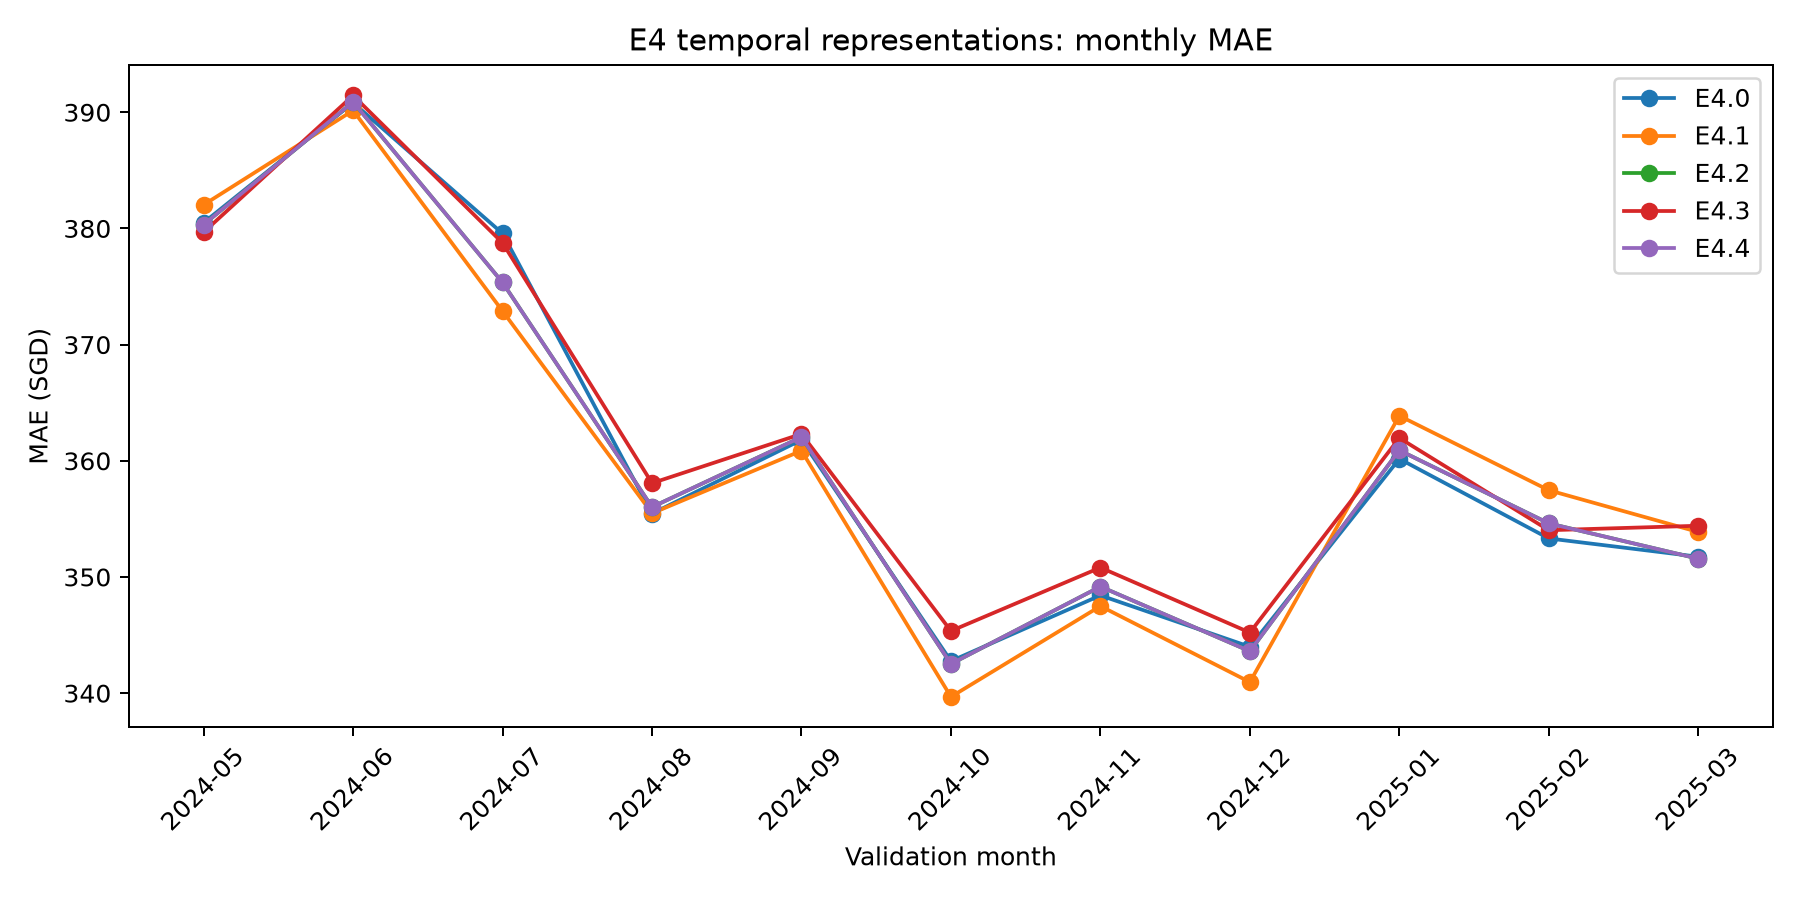

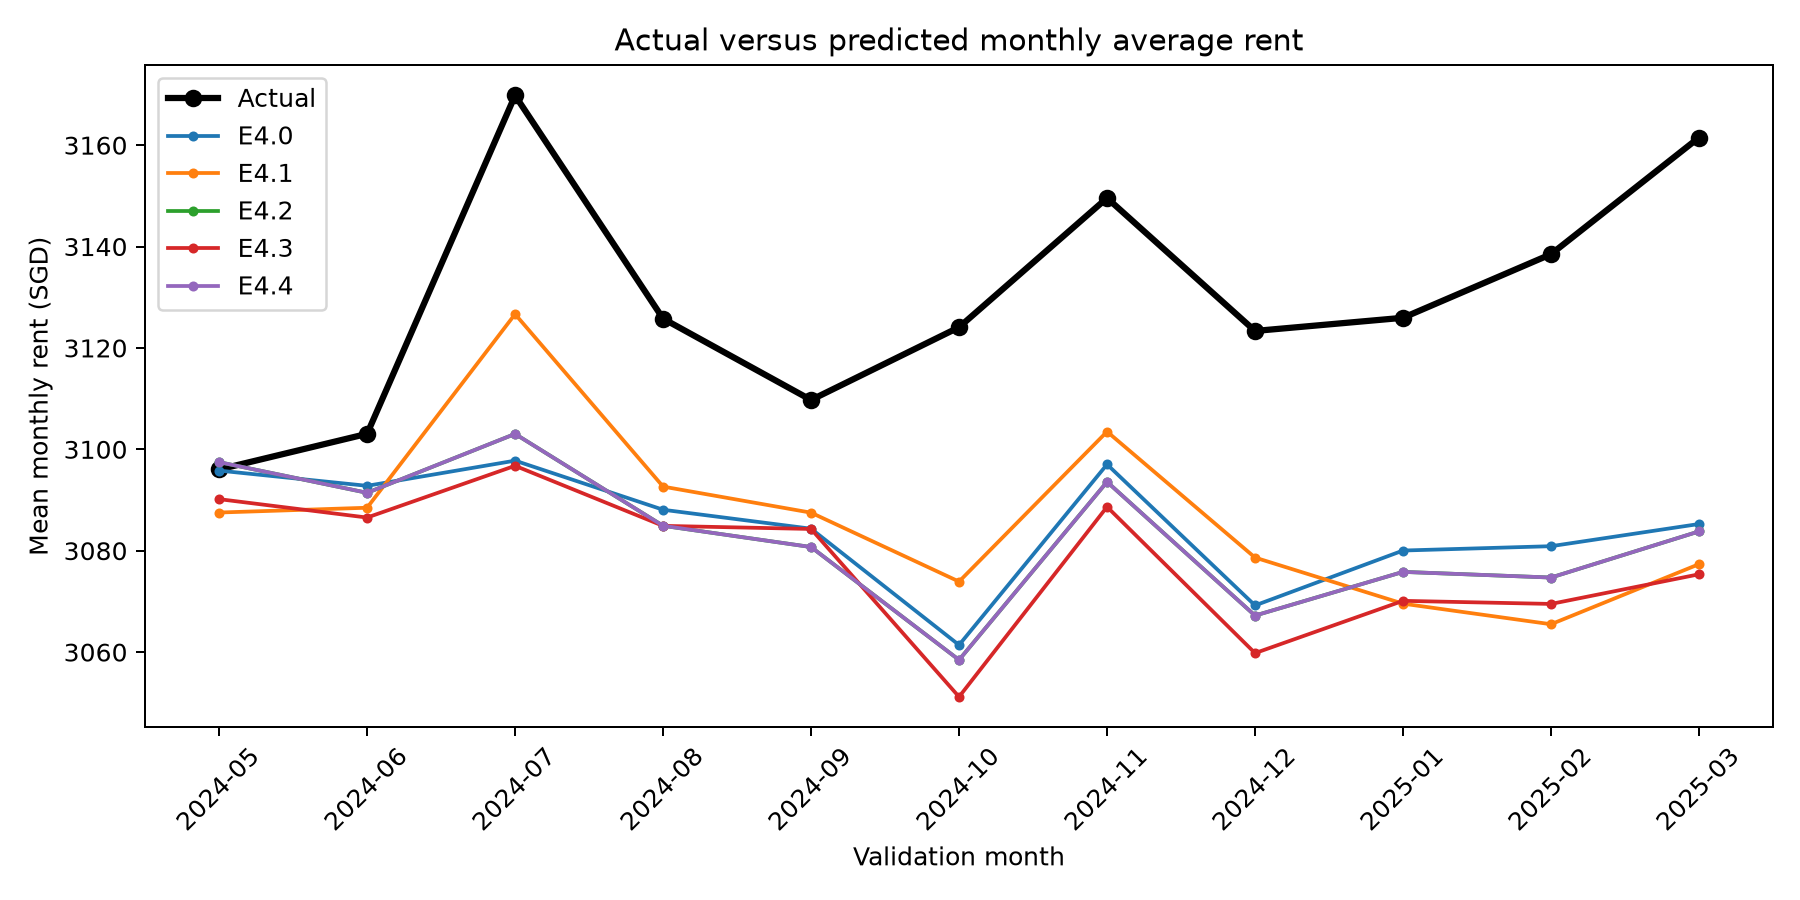

In [12]:
import os
import tempfile
# Avoid writing caches into teammates' files or requiring a writable home directory.
os.environ.setdefault("MPLCONFIGDIR", tempfile.mkdtemp(prefix="cs5228_e4_mpl_"))
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

fig, ax = plt.subplots(figsize=(10, 5))
for configuration, group in monthly.groupby("experiment", sort=True):
    ax.plot(group.month, group.MAE, marker="o", label=configuration)
ax.set(xlabel="Validation month", ylabel="MAE (SGD)", title="E4 temporal representations: monthly MAE")
ax.tick_params(axis="x", rotation=45)
ax.legend(); fig.tight_layout()
fig.savefig(phase2_dir / "monthly_mae.png", dpi=180)
plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 5))
actual = monthly[monthly.experiment == "E4.0"]
ax.plot(actual.month, actual.actual_mean, color="black", linewidth=2.5, marker="o", label="Actual")
for configuration, group in monthly.groupby("experiment", sort=True):
    ax.plot(group.month, group.predicted_mean, marker=".", label=configuration)
ax.set(xlabel="Validation month", ylabel="Mean monthly rent (SGD)", title="Actual versus predicted monthly average rent")
ax.tick_params(axis="x", rotation=45)
ax.legend(); fig.tight_layout()
fig.savefig(phase2_dir / "monthly_average_rent.png", dpi=180)
plt.close(fig)
display(Image(filename=str(phase2_dir / "monthly_mae.png")))
display(Image(filename=str(phase2_dir / "monthly_average_rent.png")))


In [13]:
PROTOCOL = """# E4 Phase 2 protocol

Five predeclared temporal configurations; fixed non-temporal inputs: floor_area_sqm,
flat_age, TOWN, FLAT_TYPE. Calendar month 1–12 and quarter 1–4 are one-hot encoded;
year is numeric. Shared cleaning and split: 117777 rows, 2021-01–2024-04 training;
31582 rows, 2024-05–2025-03 validation. All new fits use identical LightGBM parameters,
train-fitted median imputation/scaling and category encoding. No test data, validation
tuning, early stopping, auxiliary inputs or hybrid models. Pipeline fit time includes
preprocessing. Mean Error is prediction minus actual. Positive RMSE/MAE improvement
means lower error than approved E4.0.

E4.0 comparison values and predictions come only from original approved run
 e40_20261021T024110526575Z. Re-running the original notebook section creates a new
baseline run but does not substitute it into this comparison. New artifacts use a
unique UTC run directory. All exact feature lists, parameters, source/baseline hashes,
record fingerprints, versions, metrics, warnings and training checks are in run.json.

Monthly diagnostics are descriptive. Lower overall RMSE does not establish better
extrapolation, causality, statistical significance or performance on an independent
future holdout. Calendar repetition and numeric time saturation require separate
interpretation; E4.4 contains redundant temporal information. No further model or
sensitivity experiment is implemented in this phase.
"""
metadata = dict(run_id=phase2_id, phase="E4.1–E4.4 plus five-configuration diagnostics",
                baseline_source=str(BASELINE_DIR.relative_to(PROJECT_ROOT)),
                baseline_sha256=BASELINE_HASHES, baseline_metrics=baseline_record["metrics"],
                baseline_features=baseline_record["features"],
                baseline_model_params=baseline_record["model_params"],
                temporal_configurations={k:dict(numeric=v[0], categorical=v[1]) for k,v in TEMPORAL_CONFIGS.items()},
                fixed_non_temporal=dict(numeric=BASE_NUMERIC, categorical=BASE_CATEGORICAL),
                python=platform.python_version(), versions=VERSIONS,
                source_sha256=source_hashes(), record_fingerprints=record_fingerprints,
                train_period=["2021-01", "2024-04"], validation_period=["2024-05", "2025-03"],
                train_rows=len(y_train), validation_rows=len(y_valid),
                fit_time_definition="preprocessing plus model.fit; excludes predict and export",
                configurations=phase2_records)
for filename, table in (("comparison.csv", comparison), ("monthly_metrics.csv", monthly)):
    with (phase2_dir / filename).open("x") as f: table.to_csv(f, index=False)
with (phase2_dir / "run.json").open("x") as f: json.dump(metadata, f, indent=2)
with (phase2_dir / "protocol.md").open("x") as f: f.write(PROTOCOL)
print("Saved Phase 2 artifacts:", phase2_dir.relative_to(PROJECT_ROOT))
print("Warnings by configuration:", {k:v["warnings"] for k,v in phase2_records.items()})


Saved Phase 2 artifacts: experiments/e4/results/phase2_20261021T024620202600Z
Warnings by configuration: {'E4.1': ['UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names'], 'E4.2': ['UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names'], 'E4.3': ['UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names'], 'E4.4': ['UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names']}
